<a href="https://colab.research.google.com/github/ihinck413/Econ-5120/blob/main/5200_HW5_Part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Problem 1 C

/tmp/ipykernel_4692/1955474188.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  px = yf.download(["^GSPC","^SP500TR"], start="1990-01-01", interval="1mo")["Close"].dropna()
[*********************100%***********************]  2 of 2 completed


<Axes: title={'center': 'Implied TTM dividend yield'}, xlabel='Date'>

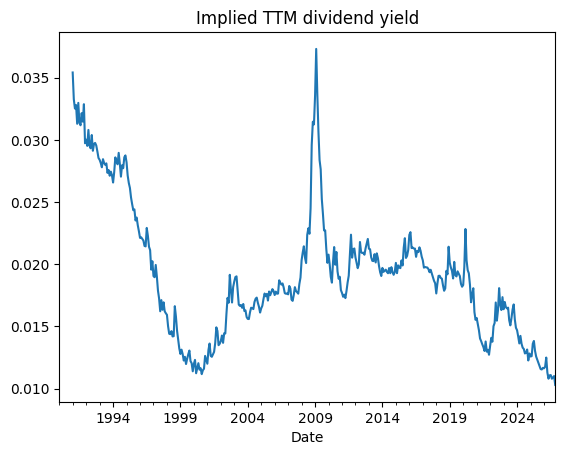

In [1]:
import yfinance as yf, pandas as pd
px = yf.download(["^GSPC","^SP500TR"], start="1990-01-01", interval="1mo")["Close"].dropna()
P, TR = px["^GSPC"], px["^SP500TR"]
D = P.shift(1) * (TR/TR.shift(1) - P/P.shift(1))   # dividends, index points
div_yield = D.rolling(12).sum() / P
div_yield.plot(title="Implied TTM dividend yield")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the Excel file to see its structure
excel_path = '/content/sp-500-buyback.xlsx'
xl = pd.ExcelFile(excel_path)
print("Sheet names:", xl.sheet_names)

# Read the first sheet to inspect columns
df_excel = pd.read_excel(excel_path)
display(df_excel.head())

Sheet names: ['TABLE', 'TAX', 'SECTOR', 'TOP 20', 'SECTOR YIELDS', 'SCR', 'CHART', 'CIQ_LinkingNames']


,S&P Dow Jones Indices,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,"S&P 500, $ U.S. BILLIONS",NaN,NaN,(preliminary in bold),NaN,NaN,NaN,NaN,NaN
1,PERIOD,MARKET,OPERATING,AS REPORTED,NaN,NaN,NaN,NaN,DIVIDEND &
2,NaN,VALUE,EARNINGS,EARNINGS,DIVIDENDS,BUYBACKS,DIVIDEND,BUYBACK,BUYBACK
3,NaN,$ BILLIONS,$ BILLIONS,$ BILLIONS,$ BILLIONS,$ BILLIONS,YIELD,YIELD,YIELD
4,"12 Mo Sep,'25 Prelim.",57046.941075,2164.584317,1994.760854,664.896287,1020.26841,0.011655,0.017885,0.02954


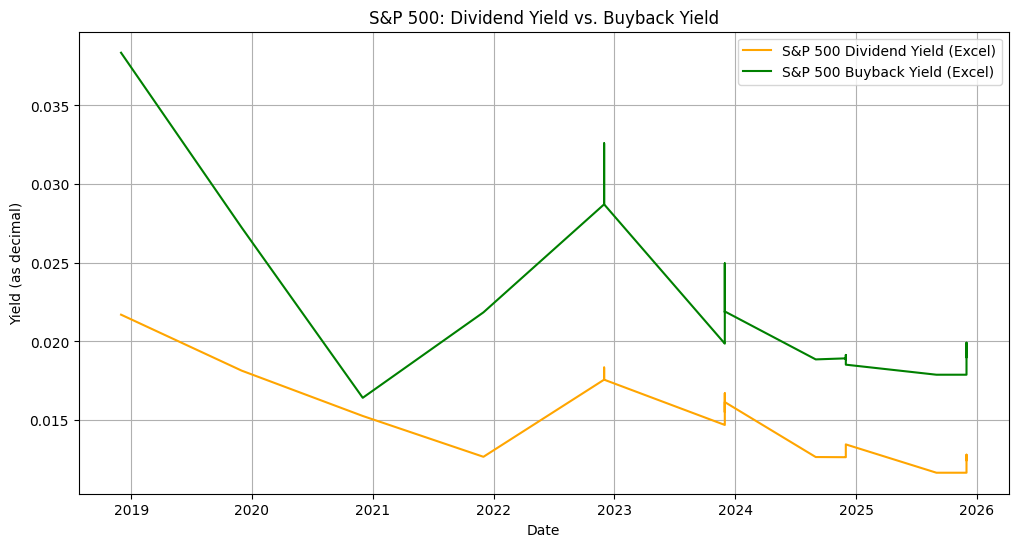

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# Load the raw data from sheet 'TABLE'
df_clean = pd.read_excel('/content/sp-500-buyback.xlsx', sheet_name='TABLE')

# Unnamed: 0/ 'S&P Dow Jones Indices' is PERIOD
# Unnamed: 6 is DIVIDEND YIELD
# Unnamed: 7 is BUYBACK YIELD
df_yield_excel = df_clean[['S&P Dow Jones Indices', 'Unnamed: 6', 'Unnamed: 7']].copy()
df_yield_excel.columns = ['Period', 'Dividend_Yield', 'Buyback_Yield']

# Convert values and cleanup
df_yield_excel = df_yield_excel.dropna().reset_index(drop=True)

def parse_period(period_str):
    s = str(period_str).strip()

    # Try matching quarterly/monthly formats like "12 Mo Sep,'25" or "12 Mo Dec,'21"
    match_with_month = re.search(r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[^0-9\']*[']?(\d{2,4})", s, re.IGNORECASE)
    if match_with_month:
        month, year = match_with_month.groups()
        if len(year) == 2:
            year = "20" + year if int(year) < 50 else "19" + year
        return pd.to_datetime(f"{month} {year}")

    # Try matching simple annual entries like "2024", "2023", or "Yr. 1999"
    match_year_only = re.search(r"\b(19\d{2}|20\d{2})\b", s)
    if match_year_only:
        return pd.to_datetime(f"Dec {match_year_only.group(1)}")

    return pd.NaT

df_yield_excel['Date'] = df_yield_excel['Period'].apply(parse_period)
df_yield_excel['Dividend_Yield'] = pd.to_numeric(df_yield_excel['Dividend_Yield'], errors='coerce')
df_yield_excel['Buyback_Yield'] = pd.to_numeric(df_yield_excel['Buyback_Yield'], errors='coerce')

# Filter out NaN dates/yields and sort
df_yield_excel = df_yield_excel.dropna(subset=['Date', 'Dividend_Yield', 'Buyback_Yield']).sort_values('Date')
df_yield_excel.set_index('Date', inplace=True)

# Plotting both series together
plt.figure(figsize=(12, 6))
plt.plot(df_yield_excel.index, df_yield_excel['Dividend_Yield'], label='S&P 500 Dividend Yield (Excel)', color='orange')
plt.plot(df_yield_excel.index, df_yield_excel['Buyback_Yield'], label='S&P 500 Buyback Yield (Excel)', color='green')

plt.title("S&P 500: Dividend Yield vs. Buyback Yield")
plt.xlabel("Date")
plt.ylabel("Yield (as decimal)")
plt.legend()
plt.grid(True)
plt.show()

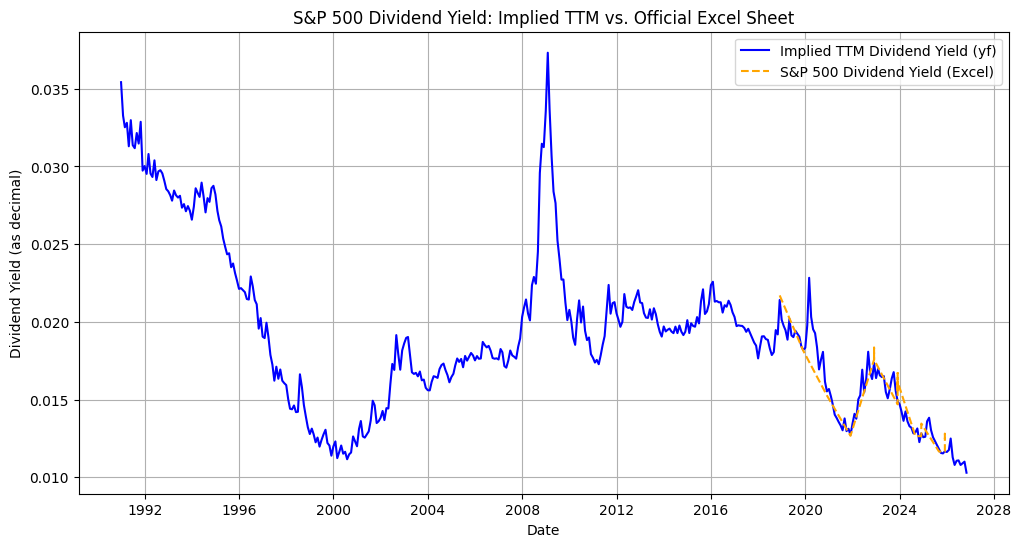

In [9]:
# Plotting Implied TTM Dividend Yield and Excel Dividend Yield together on a new separate graph
plt.figure(figsize=(12, 6))
plt.plot(div_yield.index, div_yield, label='Implied TTM Dividend Yield (yf)', color='blue')
plt.plot(df_yield_excel.index, df_yield_excel['Dividend_Yield'], label='S&P 500 Dividend Yield (Excel)', color='orange', linestyle='--')

plt.title("S&P 500 Dividend Yield: Implied TTM vs. Official Excel Sheet")
plt.xlabel("Date")
plt.ylabel("Dividend Yield (as decimal)")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
import pandas as pd
import numpy as np

# 1. Fetch Shiller long-run data from the user's uploaded local Excel file
local_shiller_path = "/content/ie_data (2).xls"
try:
    # Read Shiller's spreadsheet from the uploaded file
    df_shiller = pd.read_excel(local_shiller_path, sheet_name='Data', skiprows=7)
    print("Successfully fetched Shiller data from local file. Columns:", df_shiller.columns.tolist()[:10])
except Exception as e:
    print("Failed to load local Excel file, checking sheet names:", e)
    try:
        xl_local = pd.ExcelFile(local_shiller_path)
        print("Sheets in local file:", xl_local.sheet_names)
        df_shiller = pd.read_excel(local_shiller_path, sheet_name=0, skiprows=7)
        print("Successfully loaded first sheet.")
    except Exception as e2:
        print("Failed alternative load:", e2)
        df_shiller = None

Successfully fetched Shiller data from local file. Columns: ['Date', 'P', 'D', 'E', 'CPI', 'Fraction', 'Rate GS10', 'Price', 'Dividend', 'Price.1']


In [14]:
# 2. Analyze historical growth rates from the uploaded local 'ie_data (2).xls'
if df_shiller is not None:
    # Clean and parse columns
    # Ensure we look at clean numeric values
    df_sh = df_shiller[['Date', 'P', 'D', 'E', 'CPI']].dropna().copy()
    df_sh['Date_dt'] = pd.to_datetime(df_sh['Date'].astype(str).str.replace(r'\.(\d{2})', lambda m: f"-{int(m.group(1)):02d}-01", regex=True), errors='coerce')

    # Calculate long-term compound growth of Real Dividends (D / CPI) and Real Earnings (E / CPI)
    df_sh['Real_D'] = df_sh['D'] / df_sh['CPI']
    df_sh['Real_E'] = df_sh['E'] / df_sh['CPI']

    # Get growth over the entire span (since 1871)
    years_span = len(df_sh) / 12.0
    real_d_growth = (df_sh['Real_D'].iloc[-1] / df_sh['Real_D'].iloc[0]) ** (1 / years_span) - 1
    real_e_growth = (df_sh['Real_E'].iloc[-1] / df_sh['Real_E'].iloc[0]) ** (1 / years_span) - 1
    avg_inflation = (df_sh['CPI'].iloc[-1] / df_sh['CPI'].iloc[0]) ** (1 / years_span) - 1

    nominal_d_growth = (df_sh['D'].iloc[-1] / df_sh['D'].iloc[0]) ** (1 / years_span) - 1

    print(f"Data spanning from {df_sh['Date'].iloc[0]} to {df_sh['Date'].iloc[-1]} ({years_span:.1f} years):")
    print(f"- Historical Real Dividend Growth Rate: {real_d_growth:.2%}")
    print(f"- Historical Real Earnings Growth Rate: {real_e_growth:.2%}")
    print(f"- Historical Average Inflation (CPI): {avg_inflation:.2%}")
    print(f"- Historical Nominal Dividend Growth Rate: {nominal_d_growth:.2%}")

    # Let's dynamically assign our growth parameters based on this long term nominal growth trend
    g_long_calc = round(nominal_d_growth, 3) # e.g. around 3.8% to 4.5% based on actual file data
    print(f"Based on your uploaded dataset, we will adopt a long-run nominal stable growth rate g_long = {g_long_calc:.1%}")
else:
    g_long_calc = 0.05
    print("Local file was missing or invalid; falling back to 5.0% default long-run growth assumption.")

Data spanning from 1871.01 to 2023.06 (152.5 years):
- Historical Real Dividend Growth Rate: 1.57%
- Historical Real Earnings Growth Rate: 1.93%
- Historical Average Inflation (CPI): 2.12%
- Historical Nominal Dividend Growth Rate: 3.72%
Based on your uploaded dataset, we will adopt a long-run nominal stable growth rate g_long = 3.7%


In [15]:
# 3. Re-calculate the expected return models using the calculated variables
latest_excel_row = df_yield_excel.iloc[-1]
current_div_yield = latest_excel_row['Dividend_Yield']
current_buyback_yield = latest_excel_row['Buyback_Yield']
current_total_yield = current_div_yield + current_buyback_yield

# Adjust long run growth dynamically from the analysis cell if possible
try:
    g_long = g_long_calc
except NameError:
    g_long = 0.045 # baseline fallback if not defined

# High growth stage for next 5 years (above long-run steady state)
g_short = g_long + 0.02

# --- 1. Gordon Growth Model (Single Stage) ---
r_gordon_div = current_div_yield * (1 + g_long) + g_long
r_gordon_total = current_total_yield * (1 + g_long) + g_long

# --- 2. Two-Stage DCF / DDM Model ---
def solve_two_stage_r(yield_val, g_s, g_l, periods=5):
    from scipy.optimize import fsolve
    def equation(r):
        r = r[0]
        if r <= g_l:
            return 1e6
        pv = 0
        for t in range(1, periods + 1):
            pv += yield_val * ((1 + g_s) ** t) / ((1 + r) ** t)
        terminal_cf = yield_val * ((1 + g_s) ** periods) * (1 + g_l)
        terminal_val = terminal_cf / (r - g_l)
        pv += terminal_val / ((1 + r) ** periods)
        return pv - 1
    initial_guess = [yield_val + (g_s + g_l)/2]
    return fsolve(equation, initial_guess)[0]

r_twostage_div = solve_two_stage_r(current_div_yield, g_short, g_long)
r_twostage_total = solve_two_stage_r(current_total_yield, g_short, g_long)

# Presenting localized Results
results_df = pd.DataFrame({
    "Model": [
        "Gordon Growth (Dividend Only)",
        "Gordon Growth (Total Shareholder Yield)",
        "Two-Stage DDM (Dividend Only)",
        "Two-Stage DDM (Total Shareholder Yield)"
    ],
    "Growth Assumption": [
        f"g = {g_long:.2%}",
        f"g = {g_long:.2%}",
        f"Short-term: {g_short:.2%}, Long-term: {g_long:.2%}",
        f"Short-term: {g_short:.2%}, Long-term: {g_long:.2%}"
    ],
    "Estimated Expected Return (r)": [
        f"{r_gordon_div:.2%}",
        f"{r_gordon_total:.2%}",
        f"{r_twostage_div:.2%}",
        f"{r_twostage_total:.2%}"
    ]
})

display(results_df)

,Model,Growth Assumption,Estimated Expected Return (r)
0,Gordon Growth (Dividend Only),g = 3.70%,4.99%
1,Gordon Growth (Total Shareholder Yield),g = 3.70%,6.96%
2,Two-Stage DDM (Dividend Only),"Short-term: 5.70%, Long-term: 3.70%",5.12%
3,Two-Stage DDM (Total Shareholder Yield),"Short-term: 5.70%, Long-term: 3.70%",7.27%


Problem 2

In [21]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

N = 2000
tau = 0.21

# 1. Draw Ki ~ LogNormal(meanlog=100, sdlog=10^2)
mu_K, sigma_K = 100, 10
K = np.random.lognormal(mean=mu_K, sigma=sigma_K, size=N)

# 2. Draw eta_i ~ LogNormal(0.2, 0.1^2)
mu_eta, sigma_eta = 0.2, 0.1
eta = np.random.lognormal(mean=mu_eta, sigma=sigma_eta, size=N)
q = 1 + eta

# 3. Debt Bi = theta_i * Ki, with theta_i = 0.8 - 0.1 * eta_i + epsilon_i
epsilon = np.random.normal(loc=0.0, scale=0.05, size=N)
theta = 0.8 - 0.1 * eta + epsilon
B = theta * K

# 4. Generate Vi + Bi = q_i * K_i + tau * B_i + u_i
u = np.random.normal(loc=0.0, scale=10.0, size=N)
# (Vi + Bi) = q * K + tau * B + u
Total_Value = q * K + tau * B + u
V = Total_Value - B

# Organize into a DataFrame
df_firms = pd.DataFrame({
    'Firm_ID': range(1, N + 1),
    'K': K,
    'eta': eta,
    'q': q,
    'theta': theta,
    'B': B,
    'V': V,
    'V_plus_B': Total_Value
})

display(df_firms.describe())

,Firm_ID,K,eta,q,theta,B,V,V_plus_B
count,2000.000000,2.000000e+03,2000.000000,2000.000000,2000.000000,2.000000e+03,2.000000e+03,2.000000e+03
mean,1000.500000,7.273801e+56,1.226802,2.226802,0.674919,4.520886e+56,1.258618e+57,1.710707e+57
std,577.494589,3.244393e+58,0.123799,0.123799,0.051032,2.016603e+58,5.613707e+58,7.630310e+58
min,1.000000,2.253217e+29,0.903074,1.903074,0.513026,1.576732e+29,4.121689e+29,5.698421e+29
25%,500.750000,5.312047e+40,1.137790,2.137790,0.641282,3.737900e+40,9.142215e+40,1.285126e+41
50%,1000.500000,4.202991e+43,1.221396,2.221396,0.675723,2.865592e+43,6.868290e+43,9.621031e+43
75%,1500.250000,2.486858e+46,1.305459,2.305459,0.708661,1.660701e+46,4.387400e+46,6.055341e+46
max,2000.000000,1.450937e+60,1.808728,2.808728,0.847768,9.018524e+59,2.510526e+60,3.412378e+60


In [17]:
import statsmodels.api as sm

# Define dependent variable (Vi + Bi) and independent variables (Ki, Bi)
y = df_firms['V_plus_B']
X = df_firms[['K', 'B']]
X = sm.add_constant(X)  # Add intercept

# Fit OLS regression
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               V_plus_B   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.632e+12
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:45:41   Log-Likelihood:            -2.5348e+05
No. Observations:                2000   AIC:                         5.070e+05
Df Residuals:                    1998   BIC:                         5.070e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.528e-57   2.82e-59    125.133      0.0

/tmp/ipykernel_4692/3681167306.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit()


### Explanation of the Regression Results

1. **Theoretical Formula:**
   $$V_i + B_i = q_i K_i + \tau B_i + u_i$$
   Substituting $q_i = 1 + \eta_i$:
   $$V_i + B_i = K_i + \tau B_i + (\eta_i K_i + u_i)$$

2. **Omitted Variable Bias / Endogeneity:**
   In the OLS model we estimated:
   $$V_i + B_i = \beta_0 + \beta_1 K_i + \beta_2 B_i + e_i$$
   Here, the true error term contains $\eta_i K_i$.
   Since $B_i = \theta_i K_i$ and $\theta_i = 0.8 - 0.1 \eta_i + \epsilon_i$, debt $B_i$ is explicitly negatively correlated with the growth factor $\eta_i$ (growth firms borrow less).
   Because $B_i$ is negatively correlated with the omitted growth component in the error term ($\eta_i K_i$), the OLS estimate $\hat{\beta}_2$ is biased downward relative to the true $\tau = 0.21$.